# Question 1 (18 pts) 
We will look into the NYC flights dataset using Pandas!

## Question 1.1 (2 pts)
Load the dataset from flights.csv file given with this file into a dataframe variable named `df`

In [1]:
import pandas as pd
df = pd.read_csv('flights.csv')
# YOUR CODE HERE

In [2]:
assert df is not None
assert isinstance(df, pd.core.frame.DataFrame)

## Question 1.2 (2 pts)
Get the total count of flights for each month and display the top three months with the highest count.

In [3]:
monthly_count = df['month'].value_counts()
monthly_count = monthly_count.iloc[:3]


In [4]:
assert all(monthly_count == pd.Series([29425, 29327, 28889], index = [7, 8, 10]))

## Question 1.3 (2 pts)
First get a new dataframe with the three columns of interest 'carrier', 'month' and 'dep_delay'. Then compute the average dep_delay for each carrier and for each month. Rank the departure delays/month and filter the 1st rank carrier for each month (carrier with the lowest dep_delay for the month will get the 1st rank). Show the results in ascending order of the month

Hint: Some of the functions that can help are rank(), unstack(), stack(). 

In [5]:

df_new = df[['carrier', 'month', 'dep_delay']]

avg_delay = df_new.groupby(['month', 'carrier']).mean()
delay_rank = avg_delay.unstack().rank(1).stack()
print(delay_rank[delay_rank['dep_delay'] == 1.0])


               dep_delay
month carrier           
1     VX             1.0
2     AS             1.0
3     HA             1.0
4     HA             1.0
5     HA             1.0
6     HA             1.0
7     HA             1.0
8     HA             1.0
9     HA             1.0
10    HA             1.0
11    HA             1.0
12    HA             1.0


C:\Users\LK-El\AppData\Local\Temp\ipykernel_17028\1840653964.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  delay_rank = avg_delay.unstack().rank(1).stack()


In [6]:
# Hidden test here

## Question 1.4 (2 pts)
Find the 5 top destinations in this dataset (most number of flights to). Filter only those flights to these top 5 destinations and then show the distribution of carriers on this filtered data.

In [7]:
top_dest = df['dest'].value_counts().sort_values(ascending = False).iloc[:5].index.tolist()
print(top_dest)
top_carrier = df[df['dest'].isin(top_dest)]
top_carrier_count = top_carrier.groupby('dest').count()
top_carrier.groupby('dest').describe()

['ORD', 'ATL', 'LAX', 'BOS', 'MCO']


year                                                         month  \
        count    mean  std     min     25%     50%     75%     max    count   
dest                                                                          
ATL   17215.0  2013.0  0.0  2013.0  2013.0  2013.0  2013.0  2013.0  17215.0   
BOS   15508.0  2013.0  0.0  2013.0  2013.0  2013.0  2013.0  2013.0  15508.0   
LAX   16174.0  2013.0  0.0  2013.0  2013.0  2013.0  2013.0  2013.0  16174.0   
MCO   14082.0  2013.0  0.0  2013.0  2013.0  2013.0  2013.0  2013.0  14082.0   
ORD   17283.0  2013.0  0.0  2013.0  2013.0  2013.0  2013.0  2013.0  17283.0   

                ... minute       time_hour                              \
          mean  ...    75%   max     count          mean           std   
dest            ...                                                      
ATL   6.536509  ...   45.0  59.0   17215.0  1.372810e+09  9.014526e+06   
BOS   6.499613  ...   40.0  59.0   15508.0  1.372710e+09  8.903276e+06   
LAX   6.727093  ...   40.0  59.0   16174.0  1.373313e+09  8.834196e+06   
MCO   6.474862  ...   45.0  59.0   14082.0  1.372659e+09  9.109837e+06   
ORD   6.601342  ...   40.0  59.0   17283.0  1.372973e+09  8.716187e+06   

                                                                            
               min           25%           50%           75%           max  
dest                                                                        
ATL   1.357038e+09  1.365113e+09  1.372781e+09  1.380575e+09  1.388534e+09  
BOS   1.357034e+09  1.365019e+09  1.372766e+09  1.380316e+09  1.388545e+09  
LAX   1.357038e+09  1.366064e+09  1.373494e+09  1.380812e+09  1.388542e+09  
MCO   1.357038e+09  1.364735e+09  1.372619e+09  1.380502e+09  1.388542e+09  
ORD   1.357034e+09  1.365712e+09  1.373195e+09  1.380323e+09  1.388538e+09  

[5 rows x 120 columns]

In [8]:
import numpy as np
assert np.all(top_dest == np.array(['ORD', 'ATL', 'LAX', 'BOS', 'MCO']))

## Question 1.5 (2 pts)
Get the total count of cancelled flights in this dataset. We'll say that a cancelled flight has dep_time missing.

In [9]:
cancelled_flight_count = len(df[df['dep_time'].isnull()])

In [10]:
assert cancelled_flight_count == 8255

## Question 1.6 (2 pts)
Count all the destinations that have a letter 'K' anywhere in the name code.

In [11]:
dest_with_k = len(df[df['dest'].str.contains('K')])

In [12]:
assert dest_with_k == 4589

## Question 1.7 (2 pts)
Create a new column called speed that computes the speed as distance/air_time

In [13]:
df['speed'] = df['distance'] / df['air_time']

In [14]:
assert type(df['speed']) == pd.Series 
assert abs(df['speed'][0] - 6.1674) < 1

## Question 1.8 (4 pts)
Segment the dep_time 24 hours into 
* night from 12 midnight to 5 am
* morning from 5:01 am to 12 noon
* afternoon from 12.01 noon to 5 pm
* evening from 5.01 pm to 12 am

And then run a query to find the total flights in each segment and save that value in the given variable.


In [15]:
dep = df['dep_time']

parts_of_day_count = pd.Series({
    'night': (dep <= 500).sum(),
    'morning': dep.between(500, 1200, inclusive='right').sum(),
    'afternoon': dep.between(1200, 1700, inclusive='right').sum(),
    'evening': (dep > 1700).sum()
})

In [16]:
assert parts_of_day_count['morning'] == 129939
assert parts_of_day_count['evening'] == 98362

# Question 2 (9 pts) 
In this problem, we will do some exploratory data analytics (EDA) by using some of the visualization libraries in Python.

In [18]:
import numpy as np
import pandas as pd
import seaborn as sns
flights = pd.read_csv("flights.csv")
airports = pd.read_csv("airports.csv")
flights.describe()

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,flight,air_time,distance,hour,minute,time_hour
count,336776.0,336776.000000,336776.000000,328521.000000,336776.000000,328521.000000,328063.000000,336776.000000,327346.000000,336776.000000,327346.000000,336776.000000,336776.000000,336776.000000,3.367760e+05
mean,2013.0,6.548510,15.710787,1349.109947,1344.254840,12.639070,1502.054999,1536.380220,6.895377,1971.923620,150.686460,1039.912604,13.180247,26.230100,1.372843e+09
std,0.0,3.414457,8.768607,488.281791,467.335756,40.210061,533.264132,497.457142,44.633292,1632.471938,93.688305,733.233033,4.661316,19.300846,9.009993e+06
min,2013.0,1.000000,1.000000,1.000000,106.000000,-43.000000,1.000000,1.000000,-86.000000,1.000000,20.000000,17.000000,1.000000,0.000000,1.357034e+09
25%,2013.0,4.000000,8.000000,907.000000,906.000000,-5.000000,1104.000000,1124.000000,-17.000000,553.000000,82.000000,502.000000,9.000000,8.000000,1.365095e+09
50%,2013.0,7.000000,16.000000,1401.000000,1359.000000,-2.000000,1535.000000,1556.000000,-5.000000,1496.000000,129.000000,872.000000,13.000000,29.000000,1.372860e+09
75%,2013.0,10.000000,23.000000,1744.000000,1729.000000,11.000000,1940.000000,1945.000000,14.000000,3465.000000,192.000000,1389.000000,17.000000,44.000000,1.380625e+09
max,2013.0,12.000000,31.000000,2400.000000,2359.000000,1301.000000,2400.000000,2359.000000,1272.000000,8500.000000,695.000000,4983.000000,23.000000,59.000000,1.388549e+09


## Question 2.1 (3 pts)

Line charts are ideal to show a trend line. Draw a line chart to show monthly frequency count of flights as a trend line for the year 2013. Be sure to choose the correct data to display on the x-axis and y-axis.

Text(0, 0.5, 'Monthly Frequency')

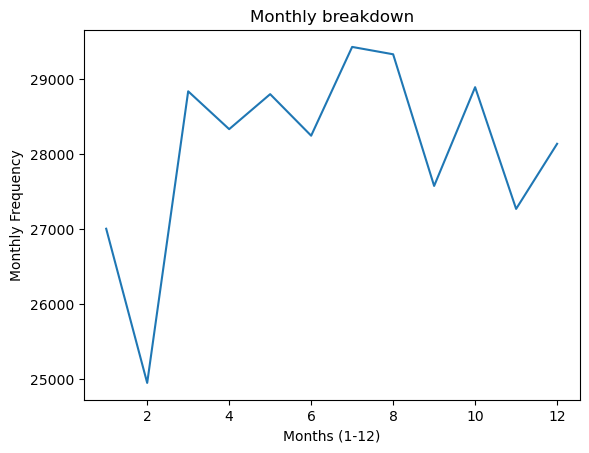

In [ ]:
data1 = flights[flights['year'] == 2013]
monthly_data = data1.groupby('month').size().reset_index(name = 'flight_count')

fig1 = sns.lineplot(data=monthly_data,
                    x = 'month',
                    y = 'flight_count')
fig1.set_title('Monthly breakdown')
fig1.set_xlabel('Months (1-12)')
fig1.set_ylabel('Monthly Frequency')

In [20]:
assert fig1.get_title() == 'Monthly breakdown'
assert fig1.get_xlabel() == 'Months (1-12)'
assert fig1.get_ylabel() == 'Monthly Frequency'
assert dict(fig1.lines[0].get_xydata())[6] == 28243

## Question 2.2 (3 pts)
Show the top 5 airports that people flew into using a bar chart. 

Text(0, 0.5, 'Total arrivals')

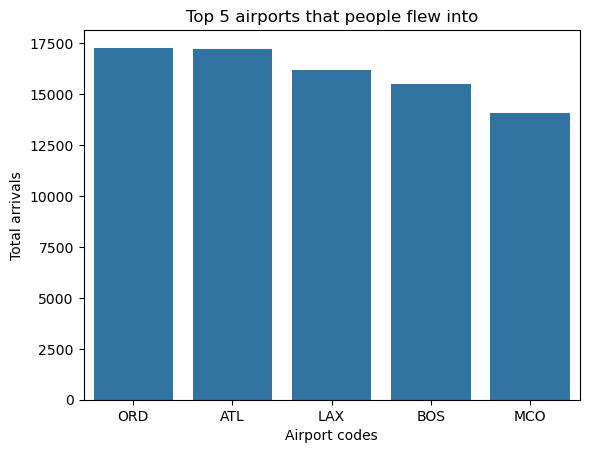

In [27]:
data2 = df.groupby('dest').size().reset_index(name = 'airport count').nlargest(5, 'airport count')
fig_2 = sns.barplot(data=data2, x='dest', y = 'airport count')

fig_2.set_title('Top 5 airports that people flew into')
fig_2.set_xlabel('Airport codes')
fig_2.set_ylabel('Total arrivals')

In [28]:
x_axis = fig_2.get_xaxis()
text1 = x_axis.get_ticklabels()[0]
assert text1.get_text() == 'ORD'
assert fig_2.get_title() == 'Top 5 airports that people flew into'
assert fig_2.get_xlabel() == 'Airport codes'
assert fig_2.get_ylabel() == 'Total arrivals'

## Question 2.3 (3 pts)

Segment the flights based on time-slots with the following criteria
* flights that depart from 00-5:59am as 'red-eye' flights
* flights that depart from 6am - 11:59am as 'morning'
* flights that depart from 12noon - 3:59pm as 'afternoon'
* flights that depart from 4pm - 11:59pm as 'evening' 

And using seaborn create a plot as shown below. PS: Feel free to choose your color palette.

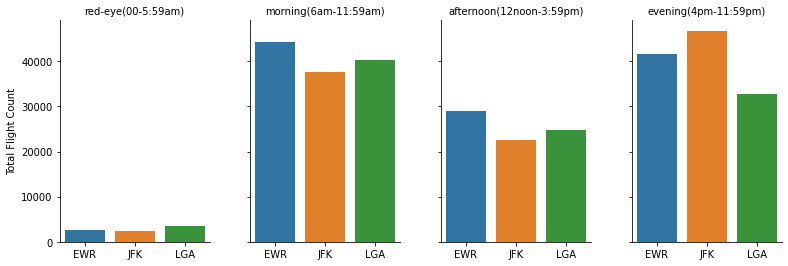

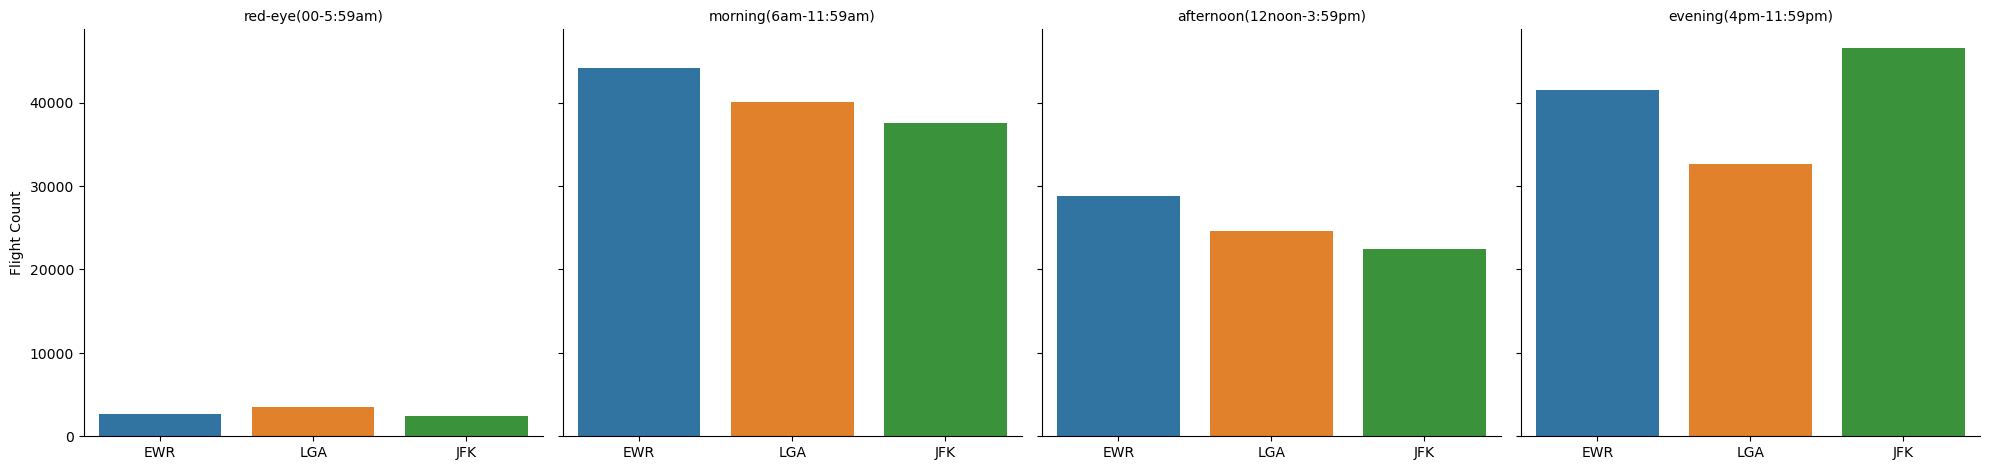

In [40]:

conditions = [
    flights['dep_time'] <= 559,                                
    flights['dep_time'].between(600, 1159, inclusive='right'), 
    flights['dep_time'].between(1200, 1559, inclusive='right'),  
    flights['dep_time'] > 1600
    ]

choices = [
    'red-eye(00-5:59am)', 
    'morning(6am-11:59am)', 
    'afternoon(12noon-3:59pm)', 
    'evening(4pm-11:59pm)'
]

flights['time_slot'] = np.select(conditions, choices, default='unknown')

data3 = flights[flights['origin'].isin(['EWR', 'JFK', 'LGA'])]

fig_3 = sns.catplot(data = data3,
                    x = 'origin',
                    col = 'time_slot',
                    hue = 'origin',
                    col_order=choices,
                    legend=False,
                    kind= 'count')

fig_3.set_axis_labels("", "Flight Count")
fig_3.set_titles(col_template="{col_name}")

In [41]:
assert fig_3.figure.get_axes()[0].get_title() == 'red-eye(00-5:59am)'
assert fig_3.figure.get_axes()[0].get_ylabel() == 'Flight Count'
assert fig_3.figure.get_axes()[1].get_title() == 'morning(6am-11:59am)'